# Comparative Implementation of ML Regression Algorithms
**Name:** Dua e Zainab  |  **Reg. No.:** FA34-BAI-027

**Problem:** House price prediction (California Housing, target = median house value in $100k)
**Models:** Linear Regression, Decision Tree, Random Forest, Neural Network, XGBoost, KNN
**Split:** 80:20 train/test (same split for all models)

In [13]:
!pip install -q xgboost

## 1. Imports

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42

## 2. Load data and preprocessing

In [15]:
data = fetch_california_housing(as_frame=True)
df = data.frame
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [16]:
print(df.describe().T)
print("\nMissing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

               count         mean          std         min         25%  \
MedInc       20640.0     3.870671     1.899822    0.499900    2.563400   
HouseAge     20640.0    28.639486    12.585558    1.000000   18.000000   
AveRooms     20640.0     5.429000     2.474173    0.846154    4.440716   
AveBedrms    20640.0     1.096675     0.473911    0.333333    1.006079   
Population   20640.0  1425.476744  1132.462122    3.000000  787.000000   
AveOccup     20640.0     3.070655    10.386050    0.692308    2.429741   
Latitude     20640.0    35.631861     2.135952   32.540000   33.930000   
Longitude    20640.0  -119.569704     2.003532 -124.350000 -121.800000   
MedHouseVal  20640.0     2.068558     1.153956    0.149990    1.196000   

                     50%          75%           max  
MedInc          3.534800     4.743250     15.000100  
HouseAge       29.000000    37.000000     52.000000  
AveRooms        5.229129     6.052381    141.909091  
AveBedrms       1.048780     1.099526     3

In [17]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# Same 80:20 split for ALL models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16512, 8) Test: (4128, 8)


## 3. Models
Feature scaling (`StandardScaler`, fitted on the training set only) is applied for Linear Regression, Neural Network and KNN. Tree-based models (Decision Tree, Random Forest, XGBoost) do not need scaling.

In [18]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED),
    "Neural Network": make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                     early_stopping=True, max_iter=500, random_state=SEED),
    ),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                            subsample=0.8, colsample_bytree=0.8, random_state=SEED),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
}

## 4. Train and evaluate (MAE, MSE, RMSE, R²)

In [19]:
rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    mse = mean_squared_error(y_test, y_pred)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 (test)": r2_score(y_test, y_pred),
        "R2 (train)": r2_score(y_train, model.predict(X_train)),
    })
    print("Trained:", name)

Trained: Linear Regression
Trained: Decision Tree
Trained: Random Forest
Trained: Neural Network
Trained: XGBoost
Trained: KNN (k=5)


## 5. Comparative performance table

In [20]:
results = pd.DataFrame(rows).set_index("Model").round(4)
results = results.sort_values("R2 (test)", ascending=False)
results.to_csv("results_table.csv")
results

,MAE,MSE,RMSE,R2 (test),R2 (train)
Model,,,,,
XGBoost,0.2935,0.2005,0.4478,0.8470,0.9318
Random Forest,0.3268,0.2540,0.5040,0.8062,0.9742
Neural Network,0.3533,0.2745,0.5239,0.7905,0.8156
Decision Tree,0.4467,0.4149,0.6441,0.6834,0.7516
KNN (k=5),0.4462,0.4324,0.6576,0.6700,0.7969
Linear Regression,0.5332,0.5559,0.7456,0.5758,0.6126


## 6. Actual vs Predicted

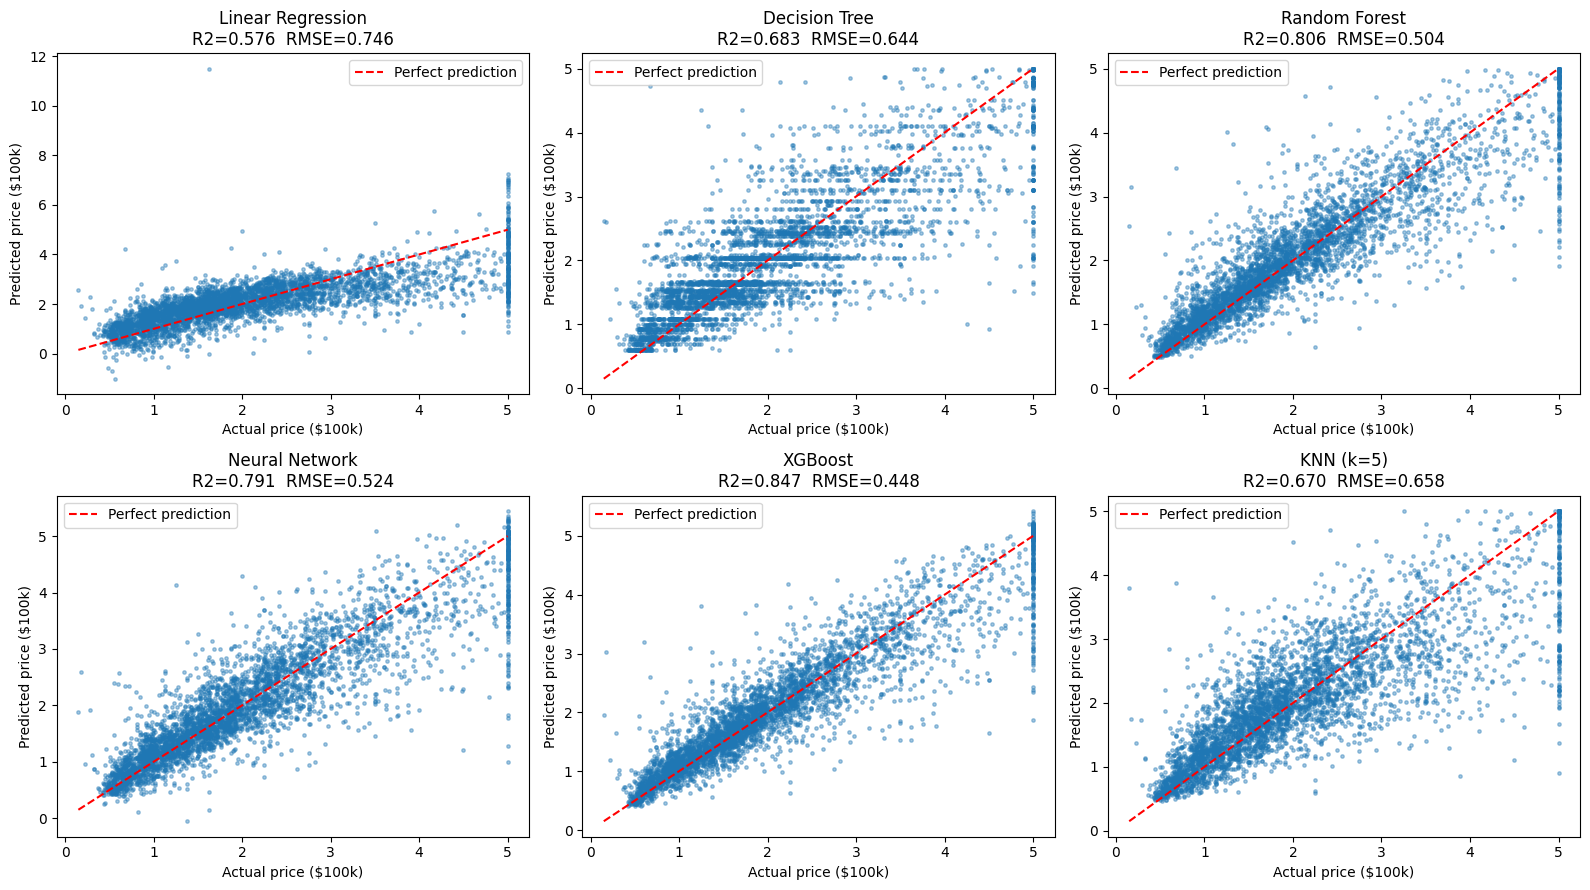

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
lims = [y_test.min(), y_test.max()]
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test, y_pred, s=6, alpha=0.4)
    ax.plot(lims, lims, "r--", lw=1.5, label="Perfect prediction")
    ax.set_title(f"{name}\nR2={r2_score(y_test, y_pred):.3f}  RMSE={np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
    ax.set_xlabel("Actual price ($100k)")
    ax.set_ylabel("Predicted price ($100k)")
    ax.legend()
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

## 7. Metric comparison charts

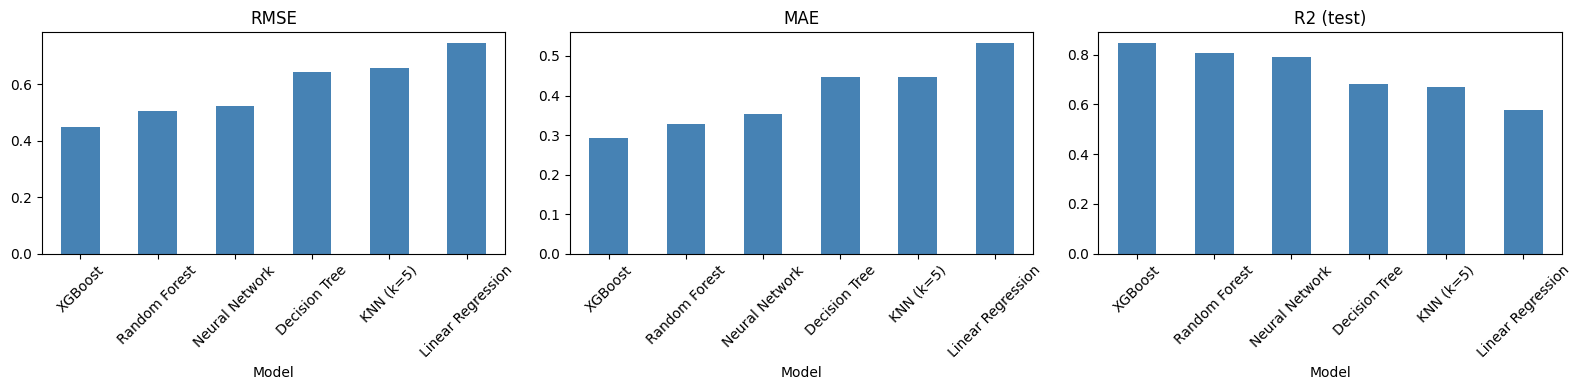

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2 (test)"]):
    results[metric].plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("metric_comparison.png", dpi=150)
plt.show()

## 8. First 10 test predictions

In [23]:
sample = pd.DataFrame({"Actual": y_test.values[:10].round(3)})
for name, p in preds.items():
    sample[name] = p[:10].round(3)
sample

,Actual,Linear Regression,Decision Tree,Random Forest,Neural Network,XGBoost,KNN (k=5)
0,0.477,0.719,0.688,0.494,0.550,0.508,0.499
1,0.458,1.764,0.805,0.736,1.219,1.027,0.765
2,5.000,2.710,4.107,4.877,5.029,5.114,4.750
3,2.186,2.839,2.389,2.550,2.631,2.395,2.877
4,2.780,2.605,1.522,2.258,2.599,2.476,2.726
5,1.587,2.012,1.910,1.651,1.544,1.674,1.779
6,1.982,2.646,2.043,2.393,2.485,2.331,2.718
7,1.575,2.169,1.634,1.664,1.548,1.625,1.925
8,3.400,2.741,2.612,2.681,2.394,2.982,2.031
9,4.466,3.916,4.983,4.887,4.472,4.799,4.956


## 9. Best model

In [24]:
best = results.index[0]
print(f"Best model: {best}")
print(results.loc[best])

Best model: XGBoost
MAE           0.2935
MSE           0.2005
RMSE          0.4478
R2 (test)     0.8470
R2 (train)    0.9318
Name: XGBoost, dtype: float64


## 10. Handwritten sample check
Verifying the handwritten calculations (5-house sample, query x = 14) with code.

In [25]:
xs = np.array([[8], [10], [12], [15], [20]])
ys = np.array([40, 50, 55, 70, 90])
q = np.array([[14]])

lr = LinearRegression().fit(xs, ys)
print(f"Linear Regression: b0={lr.intercept_:.2f}, b1={lr.coef_[0]:.3f}, pred(14)={lr.predict(q)[0]:.2f}")

dt = DecisionTreeRegressor(random_state=0).fit(xs, ys)
print("Decision Tree pred(14):", dt.predict(q)[0])

knn = KNeighborsRegressor(n_neighbors=3).fit(xs, ys)
print(f"KNN (k=3) pred(14): {knn.predict(q)[0]:.2f}")

Linear Regression: b0=7.08, b1=4.148, pred(14)=65.15
Decision Tree pred(14): 70.0
KNN (k=3) pred(14): 58.33
